# Etapa 3 · Arquitetura

| | |
|---|---|
| **Pergunta** | Que rede desenhar, do zero, para este problema? |
| **Entrada** | `entregas/01_dados/` (o que os dados pedem) e `entregas/02_avaliacao/` (a régua e a linha de base a superar). |
| **Entrega** | A rede implementada (`src/especialista/modelos/diet/`) e `entregas/03_arquitetura/`: ficha da arquitetura, diagrama, primeira medida de eficiência e resumo. |
| **Pronto quando** | (1) o CRF dá o mesmo resultado da força bruta; (2) as perdas iniciais batem com o valor teórico; (3) o gradiente chega a todos os parâmetros; (4) a resposta de um enunciado não depende do lote; (5) a rede decora um conjunto pequeno; (6) o sistema passa pela régua. |

Esta etapa **não treina** o modelo. Ela entrega a rede pronta e a prova de que está corretamente ligada. O treino é a Etapa 4.

**Artigo-âncora:** Bunk et al., *DIET: Lightweight Language Understanding for Dialogue Systems* ([arXiv 2004.09936](https://arxiv.org/abs/2004.09936)).

**Artigos de apoio, por peça**

| Peça | Artigo |
|---|---|
| Bloco Transformer | Vaswani et al., *Attention Is All You Need* ([1706.03762](https://arxiv.org/abs/1706.03762)) |
| Posição relativa na atenção | Shaw et al., *Self-Attention with Relative Position Representations* ([1803.02155](https://arxiv.org/abs/1803.02155)) |
| Normalização antes da subcamada | Xiong et al., *On Layer Normalization in the Transformer Architecture* ([2002.04745](https://arxiv.org/abs/2002.04745)) |
| N-gramas de caracteres | Bojanowski et al., *Enriching Word Vectors with Subword Information* ([1607.04606](https://arxiv.org/abs/1607.04606)) |
| CRF sobre rede neural | Lample et al., *Neural Architectures for Named Entity Recognition* ([1603.01360](https://arxiv.org/abs/1603.01360)) |

**Roteiro**

1. O que as etapas anteriores pedem da rede
2. Visão geral
3. Camada A: features
4. Camada B: tabela de features
5. Camada C: projeção e token CLS
6. Camada D: encoder com posição relativa
7. Camada E: cabeça de intenção
8. Camada F: cabeça de entidades (CRF)
9. Camada G: cabeça de máscara
10. A rede inteira: formas e parâmetros
11. A rede está bem ligada?
12. Pela régua: primeira medida de eficiência
13. O que vem do artigo e o que é escolha deste projeto
14. Entrega
15. Resposta

In [1]:
import itertools
import json
import math
import time
from collections import Counter
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, Markdown, display

from especialista import visual
from especialista.avaliacao import eficiencia, qualidade, resultados
from especialista.avaliacao.previsao import ouro
from especialista.bio import bio_para_spans
from especialista.caminhos import ENTREGAS, RAIZ, entrega
from especialista.dados import massive
from especialista.modelos.diet import Config, SistemaDiet, diagrama, ngramas
from especialista.modelos.diet.crf import CRF, restricoes_bio
from especialista.modelos.diet.features import features_do_texto

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 140)
torch.set_num_threads(1)  # medidas de CPU com um núcleo: o cenário mais barato de servir e o mais reprodutível

PASTA = entrega("03_arquitetura")
GPU = "cuda" if torch.cuda.is_available() else "cpu"

particoes, rotulos = massive.carregar_entrega()
treino, dev = particoes["train"], particoes["dev"]   # o teste não é aberto nesta etapa
base = resultados.carregar(ENTREGAS / "02_avaliacao")
linha_de_base = base[(base["particao"] == "dev") & base["sistema"].str.startswith("Linha de base")].iloc[0]


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def potencia(x):
    """Número grande em notação científica legível: 2.1e14 -> 2,1 × 10^14."""
    mantissa, expoente = f"{x:.1e}".split("e")
    return f"{mantissa.replace('.', ',')} × 10^{int(expoente)}"


print(f"PyTorch {torch.__version__} · GPU: {torch.cuda.get_device_name(0) if GPU == 'cuda' else 'não'}")

PyTorch 2.15.0+cu132 · GPU: NVIDIA GeForce RTX 3080


## 1. O que as etapas anteriores pedem da rede

A arquitetura não começa do artigo, começa do problema. Cada linha abaixo liga uma evidência medida nas Etapas 1 e 2 a uma decisão de desenho.

In [2]:
vocabulario_de_palavras = {p for tokens in treino["tokens"] for p in tokens}
palavras_dev = [p for tokens in dev["tokens"] for p in tokens]
ineditas = [p for p in palavras_dev if p not in vocabulario_de_palavras]
por_tipo = Counter(tipo for tags in treino["tags"] for tipo, _, _ in bio_para_spans(list(tags)))
tipos_com_pouco = sum(1 for t in rotulos["slot_types"] if por_tipo.get(t, 0) < 100)
maior = {p: int(particoes[p]["n_tokens"].max()) for p in massive.PARTICOES}

pd.DataFrame([
    {"evidência": f"{pts(len(ineditas) / len(palavras_dev))}% das palavras de dev nunca aparecem no treino; somar caracteres deu ganho medido na linha de base",
     "decisão": "A entrada olha dentro da palavra: n-gramas de caracteres", "camada": "A"},
    {"evidência": f"A linha de base, sem contexto, faz {pts(linha_de_base['slot_f1'])} de F1 de entidades em dev",
     "decisão": "Cada palavra precisa enxergar as vizinhas: atenção", "camada": "D"},
    {"evidência": "Na linha de base, os limites das entidades saem quebrados",
     "decisão": "Pontuar a sequência de tags inteira, não palavra por palavra: CRF", "camada": "F"},
    {"evidência": f"Enunciados curtos: mediana de {treino['n_tokens'].median():.0f} palavras, 99% com até {treino['n_tokens'].quantile(0.99):.0f}",
     "decisão": "Rede rasa: 2 blocos bastam para cada palavra alcançar todas as outras", "camada": "D"},
    {"evidência": f"O maior enunciado do treino tem {maior['train']} palavras; o do teste tem {maior['test']}",
     "decisão": "Posição relativa (distância entre palavras), que não depende do comprimento", "camada": "D"},
    {"evidência": f"{tipos_com_pouco} dos {len(rotulos['slot_types'])} tipos de entidade têm menos de 100 exemplos",
     "decisão": "Esquema de tags enxuto (BIO), com as regras do esquema fixadas no CRF", "camada": "F"},
    {"evidência": f"A linha de base já faz {pts(linha_de_base['intent_acc'])} de acurácia de intenção com um saco de features",
     "decisão": "O token de sentença (CLS) começa como esse resumo do enunciado", "camada": "C"},
    {"evidência": "Intenção e entidades andam juntas (quem pede alarme fala de hora)",
     "decisão": "Um encoder compartilhado e duas cabeças, treinadas juntas", "camada": "E, F"},
]).set_index("camada")

,evidência,decisão
camada,,
A,"3,9% das palavras de dev nunca aparecem no treino; somar caracteres deu ganho medido na linha de base",A entrada olha dentro da palavra: n-gramas de caracteres
D,"A linha de base, sem contexto, faz 49,9 de F1 de entidades em dev",Cada palavra precisa enxergar as vizinhas: atenção
F,"Na linha de base, os limites das entidades saem quebrados","Pontuar a sequência de tags inteira, não palavra por palavra: CRF"
D,"Enunciados curtos: mediana de 7 palavras, 99% com até 18",Rede rasa: 2 blocos bastam para cada palavra alcançar todas as outras
D,O maior enunciado do treino tem 32 palavras; o do teste tem 70,"Posição relativa (distância entre palavras), que não depende do comprimento"
F,30 dos 55 tipos de entidade têm menos de 100 exemplos,"Esquema de tags enxuto (BIO), com as regras do esquema fixadas no CRF"
C,"A linha de base já faz 84,5 de acurácia de intenção com um saco de features",O token de sentença (CLS) começa como esse resumo do enunciado
"E, F",Intenção e entidades andam juntas (quem pede alarme fala de hora),"Um encoder compartilhado e duas cabeças, treinadas juntas"


A última linha é o argumento central do DIET: no artigo, treinar as duas tarefas juntas subiu o F1 de entidades de 82,57 para 86,04, com perda pequena na intenção (90,90 para 90,18). Repetir essa comparação nos nossos dados fica para a Etapa 4.

## 2. Visão geral

A rede, de cima para baixo, com a forma dos dados em cada ponto para um enunciado de exemplo.

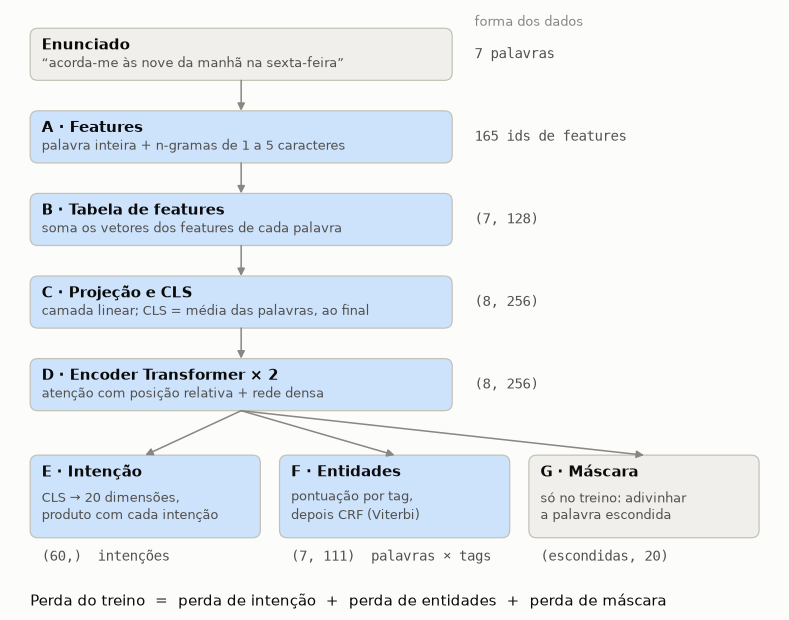

In [3]:
sistema = SistemaDiet.novo(treino, rotulos)   # pesos iniciais, sem treino
modelo, featurizador = sistema.modelo, sistema.featurizador
config = modelo.config

exemplo = treino.iloc[0]
lote_exemplo = featurizador.montar([list(exemplo.tokens)])
modelo.eval()
with torch.no_grad():
    vetores = modelo._vetores_das_palavras(lote_exemplo)
    saida = modelo.codificar(lote_exemplo)
    intencoes, emissoes = modelo(lote_exemplo)

L = len(exemplo.tokens)
formas = {
    "texto": f"{L} palavras",
    "A": f"{len(lote_exemplo.features)} ids de features",
    "B": f"{tuple(vetores.shape[1:])}",
    "C": f"({L + 1}, {config.d_modelo})",
    "D": f"({L + 1}, {config.d_modelo})",
    "E": f"({intencoes.shape[1]},)  intenções",
    "F": f"{tuple(emissoes.shape[1:])}  palavras × tags",
    "G": f"(escondidas, {config.d_rotulo})",
}
fig = diagrama.desenhar(formas, exemplo.utt)
visual.salvar(fig, PASTA, "arquitetura")
plt.show()

As seções seguintes passam por uma camada de cada vez: o que faz, por que existe e de onde veio.

## 3. Camada A: features

**O que faz.** Transforma cada palavra numa lista de *features* ligados: a própria palavra e todos os seus n-gramas de 1 a 5 caracteres. `^` e `$` marcam o começo e o fim da palavra.

**De onde vem.** É a entrada "esparsa" do DIET: *token level one-hot encodings and multi-hot encodings of character n-grams (n ≤ 5)*. As marcas de borda seguem Bojanowski et al.

**Por que.** Uma palavra nunca vista não tem o feature de palavra, mas compartilha n-gramas com palavras conhecidas. "amanhãs" não está no treino; "amanhã" está.

In [4]:
print("Features de 'manhã':")
print("  ", features_do_texto("manhã"))

nova = "amanhãs"
conhecidos = [f for f in features_do_texto(nova) if f in featurizador.vocabulario]
print(f"\n'{nova}' está no treino? {'sim' if nova in vocabulario_de_palavras else 'não'}")
print(f"  features conhecidos: {len(conhecidos)} de {len(features_do_texto(nova))}")
print("  ", conhecidos[:14], "...")

Features de 'manhã':
   ['p:manhã', 'g:m', 'g:a', 'g:n', 'g:h', 'g:ã', 'g:^m', 'g:ma', 'g:an', 'g:nh', 'g:hã', 'g:ã$', 'g:^ma', 'g:man', 'g:anh', 'g:nhã', 'g:hã$', 'g:^man', 'g:manh', 'g:anhã', 'g:nhã$', 'g:^manh', 'g:manhã', 'g:anhã$']

'amanhãs' está no treino? não
  features conhecidos: 32 de 33
   ['g:a', 'g:m', 'g:n', 'g:h', 'g:ã', 'g:s', 'g:^a', 'g:am', 'g:ma', 'g:an', 'g:nh', 'g:hã', 'g:ãs', 'g:s$'] ...


**Quantos features guardar.** Todo feature visto no treino poderia entrar no vocabulário. Mas um feature visto uma única vez não generaliza: só serve para decorar aquele exemplo, e cada feature custa uma linha na tabela da camada B. A tabela mostra o tamanho do vocabulário e a cobertura das palavras inéditas de `dev` para cada corte.

In [5]:
contagem = Counter(f for tokens in treino["tokens"] for p in tokens for f in features_do_texto(p))

linhas = []
for minimo in (1, 2, 3, 5, 10):
    mantidos = {f for f, c in contagem.items() if c >= minimo}
    cobertura = [sum(f in mantidos for f in features_do_texto(p)[1:]) / len(features_do_texto(p)[1:]) for p in ineditas]
    linhas.append({
        "contagem mínima": minimo,
        "palavras": n(sum(f.startswith("p:") for f in mantidos)),
        "n-gramas": n(sum(f.startswith("g:") for f in mantidos)),
        "total de features": n(len(mantidos)),
        "n-gramas conhecidos nas palavras inéditas de dev": pts(np.mean(cobertura)) + "%",
        "palavras inéditas sem nenhum feature": sum(1 for c in cobertura if c == 0),
    })
cortes = pd.DataFrame(linhas).set_index("contagem mínima")
cortes

,palavras,n-gramas,total de features,n-gramas conhecidos nas palavras inéditas de dev,palavras inéditas sem nenhum feature
contagem mínima,,,,,
1,6.220,34.225,40.445,"87,0%",0
2,3.092,22.110,25.202,"83,3%",0
3,2.201,17.558,19.759,"81,0%",0
5,1.452,13.228,14.680,"78,4%",0
10,892,9.308,10.200,"74,5%",0


In [6]:
por_palavra = [len(featurizador.ids(p)) for p in palavras_dev]
display(Markdown(f"""
**Decisão.** Contagem mínima de **2**: entra no vocabulário o que apareceu pelo menos duas vezes no treino. São **{n(len(featurizador))} features**. Em relação a guardar tudo, o vocabulário cai {pts(1 - len(featurizador) / len(contagem), 0)}%, e toda palavra inédita de `dev` continua com n-gramas conhecidos.

Cada palavra de `dev` liga em média {num(np.mean(por_palavra))} features (95% das palavras ligam até {np.percentile(por_palavra, 95):.0f}).

O artigo não informa esse corte. É uma escolha deste projeto, feita olhando a cobertura, sem olhar nenhum rótulo.
"""))


**Decisão.** Contagem mínima de **2**: entra no vocabulário o que apareceu pelo menos duas vezes no treino. São **25.202 features**. Em relação a guardar tudo, o vocabulário cai 38%, e toda palavra inédita de `dev` continua com n-gramas conhecidos.

Cada palavra de `dev` liga em média 20,9 features (95% das palavras ligam até 42).

O artigo não informa esse corte. É uma escolha deste projeto, feita olhando a cobertura, sem olhar nenhum rótulo.


## 4. Camada B: tabela de features

**O que faz.** Dá um vetor de 128 números a cada feature e **soma** os vetores dos features ligados de cada palavra. O resultado é um vetor de 128 números por palavra.

**De onde vem.** No DIET, o vetor esparso de zeros e uns passa por uma camada densa com pesos compartilhados entre as palavras. Somar as linhas dos features ligados é exatamente a mesma conta, sem nunca montar o vetor de 25 mil posições. A célula abaixo confere isso numericamente.

**Regularização.** O artigo aplica dropout nesses features, porque n-gramas carregam muita informação repetida. No treino, cada feature ligado é apagado com probabilidade de 20%.

In [7]:
ids = featurizador.ids("manhã")
tabela = modelo.tabela.weight.detach()

vetor_esparso = torch.zeros(len(featurizador))
vetor_esparso[ids] = 1.0
pela_camada_densa = vetor_esparso @ tabela      # camada densa aplicada ao vetor de zeros e uns
pela_soma = tabela[ids].sum(0)                  # soma das linhas dos features ligados

print(f"Vetor esparso de 'manhã': {n(len(vetor_esparso))} posições, {int(vetor_esparso.sum())} ligadas")
print(f"Tabela de features: {tuple(tabela.shape)}")
print(f"Maior diferença entre as duas contas: {(pela_camada_densa - pela_soma).abs().max().item():.1e}")

Vetor esparso de 'manhã': 25.202 posições, 24 ligadas
Tabela de features: (25202, 128)
Maior diferença entre as duas contas: 3.6e-07


## 5. Camada C: projeção e token CLS

**O que faz.**

- Uma camada linear leva cada palavra de 128 para 256 dimensões, a dimensão do Transformer.
- Acrescenta, **depois da última palavra**, o token de sentença `CLS`. A saída dele é o que a cabeça de intenção lê.

**De onde vem.** As duas coisas são do DIET. O artigo coloca o `CLS` no fim da sentença e define o seu valor inicial conforme o tipo de feature. Para vetores de palavra sem contexto (o caso do GloVe), ele usa **a média dos vetores das palavras**; é a regra adotada aqui.

**Por que essa regra.** A média dos vetores de features é um resumo "saco de palavras" do enunciado, e a Etapa 2 mostrou quanto esse resumo vale: a linha de base chega perto do modelo publicado em intenção usando só isso. O `CLS` começa desse ponto e o encoder o refina com contexto.

In [8]:
print(f"Palavras do exemplo:        {L}")
print(f"Depois da tabela (B):       {tuple(vetores.shape)}   (lote, palavras, d_features)")
print(f"Depois da projeção e CLS:   (1, {L + 1}, {config.d_modelo})   (lote, palavras + CLS, d_modelo)")
print(f"Posição do CLS na sequência: {L}  (logo depois da última palavra)")

Palavras do exemplo:        7
Depois da tabela (B):       (1, 7, 128)   (lote, palavras, d_features)
Depois da projeção e CLS:   (1, 8, 256)   (lote, palavras + CLS, d_modelo)
Posição do CLS na sequência: 7  (logo depois da última palavra)


## 6. Camada D: encoder com posição relativa

**O que faz.** Dois blocos Transformer. Em cada bloco, cada palavra consulta todas as outras (atenção) e depois passa por uma pequena rede densa. É aqui que "nove" fica sabendo que está ao lado de "da manhã".

**De onde vem.** *We use a 2 layer transformer with relative position attention*; a dimensão é 256. O bloco é o de Vaswani et al.; a posição relativa é a de Shaw et al.

**Posição relativa.** A atenção, sozinha, não sabe a ordem das palavras. A solução mais comum é somar à entrada um vetor por posição absoluta (1ª, 2ª, 3ª...). Shaw et al. fazem diferente: a pontuação de atenção entre duas palavras recebe um termo que depende só da **distância** entre elas.

$$\text{pontuação}(i, j) = \frac{q_i \cdot (k_j + a_{j-i})}{\sqrt{d}}$$

`a` é uma tabela aprendida com um vetor por distância, de −5 a +5. Distâncias maiores usam o vetor do extremo. A figura mostra a distância que cada palavra do exemplo "enxerga" para cada outra.

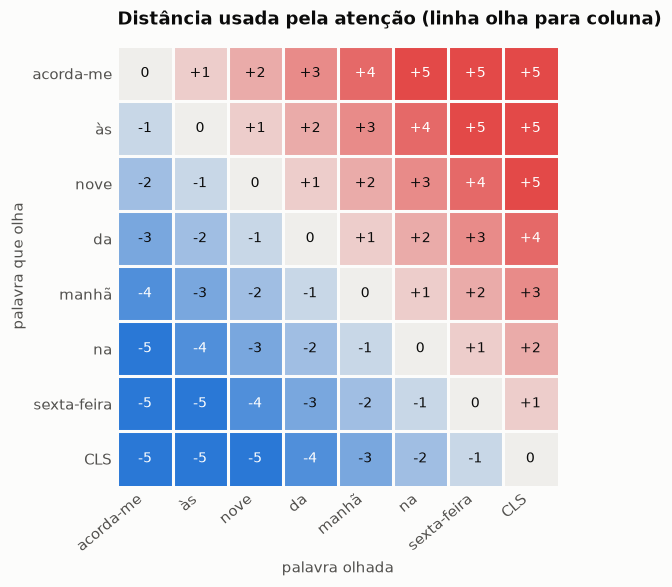

In [9]:
nomes = [*exemplo.tokens, "CLS"]
posicoes = np.arange(len(nomes))
distancias = np.clip(posicoes[None, :] - posicoes[:, None], -config.distancia_max, config.distancia_max)

# divergente: azul para trás, vermelho para a frente, cinza neutro no zero
from matplotlib.colors import LinearSegmentedColormap
mapa = LinearSegmentedColormap.from_list("distancia", ["#2a78d6", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.imshow(distancias, cmap=mapa, vmin=-config.distancia_max, vmax=config.distancia_max)
for i in range(len(nomes)):
    for j in range(len(nomes)):
        forte = abs(distancias[i, j]) >= 4
        ax.text(j, i, f"{distancias[i, j]:+d}" if distancias[i, j] else "0", ha="center", va="center",
                fontsize=9, color="#ffffff" if forte else visual.TINTA)
ax.set_xticks(posicoes, nomes, rotation=40, ha="right")
ax.set_yticks(posicoes, nomes)
ax.set_xticks(posicoes - 0.5, minor=True)
ax.set_yticks(posicoes - 0.5, minor=True)
ax.grid(which="minor", color=visual.SUPERFICIE, linewidth=2)   # vão entre as células
ax.tick_params(which="minor", length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_title("Distância usada pela atenção (linha olha para coluna)")
ax.set_xlabel("palavra olhada")
ax.set_ylabel("palavra que olha")
visual.salvar(fig, PASTA, "posicao_relativa")
plt.show()

In [10]:
longo = " ".join(["toca"] * 100)
resposta = sistema.prever([longo])[0]
display(Markdown(f"""
**Por que aqui.** O maior enunciado do treino tem {maior['train']} palavras e o do teste tem {maior['test']}. Uma tabela de posições absolutas não teria vetor treinado para a posição 33 em diante. Com distância relativa, a rede trata um enunciado de 100 palavras sem nenhuma mudança (teste feito agora: resposta devolvida, intenção `{resposta.intent}`, ainda sem sentido porque a rede não foi treinada).

**Dentro do bloco**, três escolhas que o artigo do DIET não detalha:

| Escolha | Valor | Origem |
|---|---|---|
| Cabeças de atenção | {config.n_cabecas} | padrão da implementação de referência do DIET (Rasa) |
| Largura da rede densa | {n(config.d_ffn)} (4 × {config.d_modelo}), ativação ReLU | proporção e ativação de Vaswani et al. |
| Normalização | antes de cada subcamada | Xiong et al.: treina estável sem aquecimento da taxa de aprendizado |

A atenção é escrita com camadas lineares à vista (consulta, chave, valor, saída), sem o módulo pronto do PyTorch. Cada matriz tem nome próprio, o que simplifica a poda e a quantização das Etapas 7 e 8.
"""))


**Por que aqui.** O maior enunciado do treino tem 32 palavras e o do teste tem 70. Uma tabela de posições absolutas não teria vetor treinado para a posição 33 em diante. Com distância relativa, a rede trata um enunciado de 100 palavras sem nenhuma mudança (teste feito agora: resposta devolvida, intenção `transport_traffic`, ainda sem sentido porque a rede não foi treinada).

**Dentro do bloco**, três escolhas que o artigo do DIET não detalha:

| Escolha | Valor | Origem |
|---|---|---|
| Cabeças de atenção | 4 | padrão da implementação de referência do DIET (Rasa) |
| Largura da rede densa | 1.024 (4 × 256), ativação ReLU | proporção e ativação de Vaswani et al. |
| Normalização | antes de cada subcamada | Xiong et al.: treina estável sem aquecimento da taxa de aprendizado |

A atenção é escrita com camadas lineares à vista (consulta, chave, valor, saída), sem o módulo pronto do PyTorch. Cada matriz tem nome próprio, o que simplifica a poda e a quantização das Etapas 7 e 8.


## 7. Camada E: cabeça de intenção

**O que faz.** Leva a saída do `CLS` para um espaço de 20 dimensões. Cada intenção também tem um vetor de 20 dimensões, aprendido. A pontuação de uma intenção é o **produto interno** entre os dois; ganha a maior.

**De onde vem.** É a formulação do DIET: *embedded into a single semantic vector space*, com vetores em ℝ²⁰ e perda de produto interno.

**Um desvio declarado.** O artigo compara a intenção certa com uma amostra das erradas, porque a mesma arquitetura atende casos com milhares de rótulos. Com 60 intenções, comparamos com **todas**. É a versão exata da mesma perda, e não uma aproximação.

In [11]:
print(f"Saída do CLS:               ({config.d_modelo},)")
print(f"No espaço de rótulos:       ({config.d_rotulo},)")
print(f"Vetores das intenções:      {tuple(modelo.vetor_da_intencao.shape)}   (intenções, d_rotulo)")
print(f"Pontuações:                 {tuple(intencoes.shape[1:])}   uma por intenção")
print(f"\nSem treino, as pontuações são quase iguais. Probabilidade máxima: {num(intencoes.softmax(-1).max().item(), 3)}"
      f"  (uniforme seria {num(1 / intencoes.shape[1], 3)})")

Saída do CLS:               (256,)
No espaço de rótulos:       (20,)
Vetores das intenções:      (60, 20)   (intenções, d_rotulo)
Pontuações:                 (60,)   uma por intenção

Sem treino, as pontuações são quase iguais. Probabilidade máxima: 0,028  (uniforme seria 0,017)


## 8. Camada F: cabeça de entidades (CRF)

**O que faz.** Uma camada linear dá, a cada palavra, uma pontuação por tag (as *emissões*). O CRF acrescenta uma pontuação por **par de tags vizinhas** (as *transições*) e escolhe a melhor sequência inteira.

**De onde vem.** *A sequence of entity labels is predicted through a Conditional Random Field tagging layer on top of the transformer output.* A perda é a de Lample et al.

**Por que.** Escolher a tag de cada palavra separadamente ignora que tags vizinhas dependem uma da outra: `I-time` só faz sentido depois de `B-time` ou `I-time`. Foi o que derrubou a linha de base na Etapa 2.

$$\text{pontuação}(\text{tags}) = \text{início}_{t_1} + \sum_i \text{emissão}_{i,\,t_i} + \sum_i \text{transição}_{t_i,\,t_{i+1}} + \text{fim}_{t_n}$$

- **Treino:** maximizar a probabilidade da sequência certa entre todas as possíveis. A soma sobre todas sai do algoritmo *forward*.
- **Inferência:** a sequência de maior pontuação sai do algoritmo de *Viterbi*.

### 8.1 Conferência contra a força bruta

Com poucas tags e sequências curtas, dá para listar todas as sequências e conferir os dois algoritmos.

In [12]:
tags_de_teste = ["O", "B-a", "I-a", "B-b", "I-b"]
torch.manual_seed(0)
crf_teste = CRF(len(tags_de_teste), *restricoes_bio(tags_de_teste))
for p in crf_teste.parameters():
    torch.nn.init.normal_(p)

linhas, crf_ok = [], True
with torch.no_grad():
    for comprimento in (1, 2, 3, 4, 5):
        emissoes_teste = torch.randn(1, comprimento, len(tags_de_teste))
        real_teste = torch.ones(1, comprimento, dtype=torch.bool)
        todas = torch.tensor(list(itertools.product(range(len(tags_de_teste)), repeat=comprimento)))
        pontos = crf_teste.pontuacao(emissoes_teste.expand(len(todas), -1, -1), todas, real_teste.expand(len(todas), -1))
        soma_bruta, melhor_bruta = torch.logsumexp(pontos, 0).item(), todas[pontos.argmax()].tolist()
        soma_forward = crf_teste.particao(emissoes_teste, real_teste).item()
        melhor_viterbi = crf_teste.decodificar(emissoes_teste, real_teste)[0]
        crf_ok &= abs(soma_bruta - soma_forward) < 1e-3 and melhor_bruta == melhor_viterbi
        linhas.append({
            "palavras": comprimento,
            "sequências possíveis": n(len(todas)),
            "soma pela força bruta": num(soma_bruta, 4),
            "soma pelo forward": num(soma_forward, 4),
            "Viterbi = melhor da força bruta": "sim" if melhor_bruta == melhor_viterbi else "NÃO",
        })
pd.DataFrame(linhas).set_index("palavras")

,sequências possíveis,soma pela força bruta,soma pelo forward,Viterbi = melhor da força bruta
palavras,,,,
1,5,"1,6470","1,6470",sim
2,25,"3,4508","3,4508",sim
3,125,"6,5821","6,5821",sim
4,625,"9,4925","9,4925",sim
5,3.125,"10,6885","10,6885",sim


### 8.2 As regras do esquema ficam fixas

O esquema BIO tem regras: uma sequência não começa com `I-`, e `I-x` só vem depois de `B-x` ou `I-x`. Em vez de esperar que a rede aprenda isso, as transições proibidas recebem uma penalidade fixa. A rede nunca devolve uma sequência malformada, e não gasta dados aprendendo o que já se sabe.

In [13]:
proibida, inicio_proibido = restricoes_bio(rotulos["tags"])
tags = rotulos["tags"]
indice = {t: i for i, t in enumerate(tags)}

# as sequências do treino respeitam as regras? (se não respeitassem, a perda explodiria)
violacoes = sum(
    inicio_proibido[indice[seq[0]]].item() + sum(proibida[indice[a], indice[b]].item() for a, b in zip(seq, seq[1:]))
    for seq in treino["tags"]
)

# quantas sequências de tags são válidas para um enunciado de 7 palavras?
permitida = (~proibida).double()
validas = ((~inicio_proibido).double() @ torch.linalg.matrix_power(permitida, 6)).sum().item()

display(Markdown(f"""
- Tags: **{len(tags)}** (`O`, mais `B-` e `I-` para cada um dos {len(rotulos['slot_types'])} tipos).
- Transições possíveis: {n(len(tags) ** 2)}. Proibidas pelo esquema: **{n(proibida.sum().item())}** ({pts(proibida.float().mean().item(), 0)}%).
- Violações nas sequências do treino: **{violacoes}**.
- Para um enunciado de 7 palavras, as regras reduzem as sequências possíveis de {potencia(len(tags) ** 7)} para {potencia(validas)}.

**Por que BIO, e não BILOU.** Nos conjuntos em que mediu entidades por limite exato, o DIET usou BILOU, que tem quatro tags por tipo. A implementação de referência recomenda BILOU só com mais de 100 exemplos por tipo de entidade, e aqui {tipos_com_pouco} dos {len(rotulos['slot_types'])} tipos ficam abaixo disso. BIO tem duas tags por tipo e é o formato dos dados da Etapa 1.
"""))


- Tags: **111** (`O`, mais `B-` e `I-` para cada um dos 55 tipos).
- Transições possíveis: 12.321. Proibidas pelo esquema: **5.995** (49%).
- Violações nas sequências do treino: **0**.
- Para um enunciado de 7 palavras, as regras reduzem as sequências possíveis de 2,1 × 10^14 para 1,9 × 10^12.

**Por que BIO, e não BILOU.** Nos conjuntos em que mediu entidades por limite exato, o DIET usou BILOU, que tem quatro tags por tipo. A implementação de referência recomenda BILOU só com mais de 100 exemplos por tipo de entidade, e aqui 30 dos 55 tipos ficam abaixo disso. BIO tem duas tags por tipo e é o formato dos dados da Etapa 1.


## 9. Camada G: cabeça de máscara

**O que faz.** Só existe no treino. Esconde 15% das palavras da entrada e pede que a rede, pelo contexto, reconheça qual era a palavra original.

**De onde vem.** É a terceira perda do DIET, inspirada no treino do BERT. A receita é a do artigo: das palavras escolhidas, 70% viram um vetor especial de máscara, 10% viram outra palavra ao acaso e 20% ficam como estão. A saída da rede na posição escondida e a palavra original são comparadas no mesmo tipo de espaço de 20 dimensões.

**Por que.** O artigo propõe a máscara como regularização: a rede precisa aprender features gerais do texto, não só os que separam as classes. Na ablação do DIET, **sem embeddings pré-treinados, que é o nosso caso, a máscara ajudou** (intenção de 87,10 para 88,19; entidades de 83,88 para 85,12). Com embeddings pré-treinados, não ajudou. Fica ligada por padrão; a Etapa 4 mede nos nossos dados se ela se paga.

**Um desvio declarado.** O artigo compara a palavra certa com palavras erradas sorteadas. Aqui as erradas são as outras palavras escondidas do mesmo lote.

In [14]:
torch.manual_seed(0)
lote_demo = sistema.lote(treino.iloc[:64])
modelo.train()
with torch.no_grad():
    saida_treino = modelo.codificar(lote_demo, esconder=True)
modelo.eval()

escondidas = int(saida_treino["escolhidas"].sum())
palavras_no_lote = int(lote_demo.comprimentos.sum())
print(f"Lote de 64 enunciados: {palavras_no_lote} palavras, {escondidas} escolhidas ({escondidas / palavras_no_lote:.0%}).")

Lote de 64 enunciados: 410 palavras, 59 escolhidas (14%).


## 10. A rede inteira: formas e parâmetros

### 10.1 Um enunciado atravessando a rede

In [15]:
intencao_prevista, caminho = modelo.prever(lote_exemplo)
pd.DataFrame([
    {"ponto": "Entrada", "o que é": "texto", "forma": f"{L} palavras", "exemplo": exemplo.utt},
    {"ponto": "A. Features", "o que é": "ids dos features ligados", "forma": f"{len(lote_exemplo.features)} ids",
     "exemplo": f"{len(featurizador.ids(exemplo.tokens[0]))} para '{exemplo.tokens[0]}'"},
    {"ponto": "B. Tabela de features", "o que é": "um vetor por palavra", "forma": str(tuple(vetores.shape)), "exemplo": ""},
    {"ponto": "C. Projeção e CLS", "o que é": "palavras + CLS", "forma": f"(1, {L + 1}, {config.d_modelo})", "exemplo": ""},
    {"ponto": "D. Encoder", "o que é": "cada posição com contexto", "forma": f"(1, {L + 1}, {config.d_modelo})", "exemplo": ""},
    {"ponto": "E. Intenção", "o que é": "uma pontuação por intenção", "forma": str(tuple(intencoes.shape)), "exemplo": "a maior vence"},
    {"ponto": "F. Entidades", "o que é": "uma pontuação por palavra e tag", "forma": str(tuple(emissoes.shape)),
     "exemplo": f"Viterbi devolve {len(caminho[0])} tags"},
]).set_index("ponto")

,o que é,forma,exemplo
ponto,,,
Entrada,texto,7 palavras,acorda-me às nove da manhã na sexta-feira
A. Features,ids dos features ligados,165 ids,43 para 'acorda-me'
B. Tabela de features,um vetor por palavra,"(1, 7, 128)",
C. Projeção e CLS,palavras + CLS,"(1, 8, 256)",
D. Encoder,cada posição com contexto,"(1, 8, 256)",
E. Intenção,uma pontuação por intenção,"(1, 60)",a maior vence
F. Entidades,uma pontuação por palavra e tag,"(1, 7, 111)",Viterbi devolve 7 tags


### 10.2 Onde estão os parâmetros

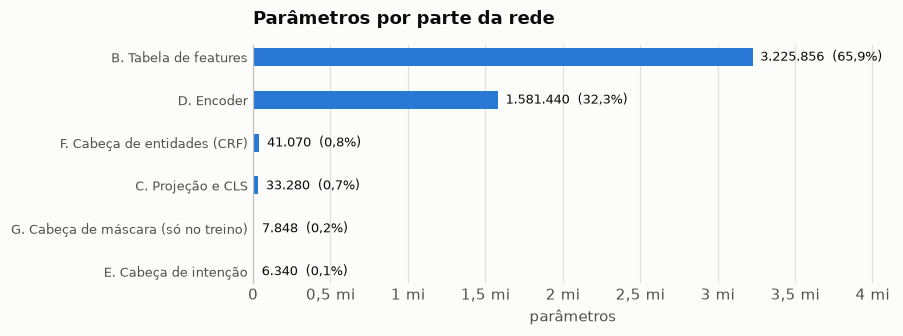


**Leitura.**

- A rede tem **4.895.834 parâmetros**: 55 vezes menos que o XLM-R Base da referência publicada (270.000.000) e a mesma ordem de grandeza da linha de base (3.940.300).
- **66% dos parâmetros estão na tabela de features**, não no Transformer. Isso muda a conta das Etapas 7 e 8: podar o encoder mexe em menos de um terço do modelo, e o tamanho final depende de como a tabela for tratada.
- As três cabeças juntas somam 55.258 parâmetros. O espaço de 20 dimensões do DIET mantém as cabeças minúsculas.
- A cabeça de máscara (7.848) é descartada depois do treino.


In [16]:
partes = pd.Series(modelo.parametros_por_parte())
total = int(partes.sum())
assert total == sistema.parametros

fig, ax = visual.barras_ranqueadas(
    partes, "Parâmetros por parte da rede", "parâmetros",
    destacar={nome: f"{n(valor)}  ({pts(valor / total)}%)" for nome, valor in partes.items()},
)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e6:g} mi".replace(".", ",") if v else "0"))
ax.margins(x=0.28)
visual.salvar(fig, PASTA, "parametros")
plt.show()

xlmr = massive.REFERENCIA["XLM-R Base"]["parametros"]
display(Markdown(f"""
**Leitura.**

- A rede tem **{n(total)} parâmetros**: {num(xlmr / total, 0)} vezes menos que o XLM-R Base da referência publicada ({n(xlmr)}) e a mesma ordem de grandeza da linha de base ({n(linha_de_base['parametros'])}).
- **{pts(partes['B. Tabela de features'] / total, 0)}% dos parâmetros estão na tabela de features**, não no Transformer. Isso muda a conta das Etapas 7 e 8: podar o encoder mexe em menos de um terço do modelo, e o tamanho final depende de como a tabela for tratada.
- As três cabeças juntas somam {n(partes[partes.index.str[0].isin(list('EFG'))].sum())} parâmetros. O espaço de 20 dimensões do DIET mantém as cabeças minúsculas.
- A cabeça de máscara ({n(partes['G. Cabeça de máscara (só no treino)'])}) é descartada depois do treino.
"""))

## 11. A rede está bem ligada?

Uma rede pode rodar sem erro e estar errada: uma máscara invertida, um rótulo desalinhado, uma parte que não recebe gradiente. Quatro testes pegam esses erros antes de gastar tempo de treino.

### 11.1 As perdas iniciais batem com a teoria

Antes de treinar, a rede não sabe nada, e a perda de quem não sabe nada tem valor conhecido:

- **Intenção:** chutar igualmente entre 60 classes dá perda ln(60).
- **Entidades:** com transições e emissões perto de zero, toda sequência válida tem quase a mesma pontuação, e a perda é o logaritmo do número de sequências válidas.
- **Máscara:** reconhecer uma palavra entre M escondidas, no chute, dá ln(M).

In [17]:
torch.manual_seed(0)
modelo.train()
with torch.no_grad():
    inicial = {k: float(v) for k, v in modelo.perda(lote_demo).items()}
    escondidas_agora = int(modelo.codificar(lote_demo, esconder=True)["escolhidas"].sum())
modelo.eval()

# número de sequências BIO válidas para cada comprimento do lote
inicio_ok = (~inicio_proibido).double()
log_validas = np.mean([
    math.log((inicio_ok @ torch.linalg.matrix_power(permitida, c - 1)).sum().item())
    for c in lote_demo.comprimentos.tolist()
])
teoria = {"intencao": math.log(len(rotulos["intents"])), "entidades": log_validas, "mascara": math.log(escondidas_agora)}

perdas_iniciais = pd.DataFrame({
    "valor teórico": {k: num(v, 2) for k, v in teoria.items()},
    "medido na rede sem treino": {k: num(inicial[k], 2) for k in teoria},
    "diferença": {k: f"{100 * (inicial[k] / teoria[k] - 1):+.0f}%" for k in teoria},
}).rename(index={"intencao": "Intenção", "entidades": "Entidades", "mascara": "Máscara"})
perdas_ok = all(abs(inicial[k] / teoria[k] - 1) < 0.15 for k in teoria)
perdas_iniciais

,valor teórico,medido na rede sem treino,diferença
Intenção,"4,09","4,11",+0%
Entidades,"25,88","25,98",+0%
Máscara,"4,37","4,40",+1%


A máscara é sorteada a cada passagem, então o M do valor teórico é o de um sorteio parecido, não o mesmo; a comparação é de ordem de grandeza. O critério é ficar a menos de 15% do valor teórico.

### 11.2 O gradiente chega a todos os parâmetros

Um parâmetro que nunca recebe gradiente nunca aprende. Depois de uma passagem de treino, todos os tensores de parâmetros precisam ter gradiente diferente de zero.

In [18]:
torch.manual_seed(0)
modelo.train()
modelo.zero_grad()
modelo.perda(lote_demo)["total"].backward()
sem_gradiente = [nome for nome, p in modelo.named_parameters() if p.grad is None or not p.grad.any()]
modelo.zero_grad()
modelo.eval()

gradiente_ok = not sem_gradiente
print(f"Tensores de parâmetros: {len(list(modelo.named_parameters()))}")
print(f"Sem gradiente:          {len(sem_gradiente)} {sem_gradiente or ''}")

Tensores de parâmetros: 53
Sem gradiente:          0 


### 11.3 A resposta não depende do lote

No treino, enunciados de tamanhos diferentes vão juntos num lote, e os curtos são completados com posições vazias. Se essas posições vazarem para a conta, a resposta de um enunciado muda conforme os vizinhos de lote. O teste: prever 200 enunciados de `dev` juntos e um por um.

In [19]:
amostra = list(dev["utt"].iloc[:200])
juntos = sistema.prever(amostra)
um_a_um = [sistema.prever([texto])[0] for texto in amostra]
lote_ok = juntos == um_a_um

with torch.no_grad():
    no_lote, _ = modelo(sistema.lote(dev.iloc[:200]))
    sozinho = torch.cat([modelo(sistema.lote(dev.iloc[[i]]))[0] for i in range(200)])
print(f"Respostas idênticas nos 200 enunciados: {'sim' if lote_ok else 'NÃO'}")
print(f"Maior diferença nas pontuações de intenção: {(no_lote - sozinho).abs().max().item():.1e}")

Respostas idênticas nos 200 enunciados: sim
Maior diferença nas pontuações de intenção: 7.7e-07


### 11.4 A rede decora um conjunto pequeno

O teste mais importante antes de treinar de verdade: dar à rede 64 exemplos e ver se ela consegue decorá-los. Se não conseguir, o defeito está na rede, na perda ou no alinhamento dos rótulos, e treinar com o conjunto inteiro só esconderia o problema.

Aqui a rede treina 300 passos sempre no mesmo lote. Isso **não é** o treino do modelo; é um teste de que ele consegue aprender.

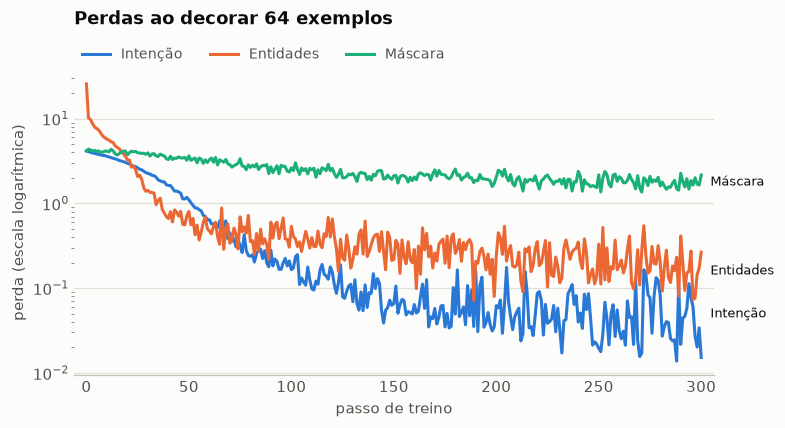

passo,0,25,50,75,100,125,150,175,200,225,250,275,300
exact_match nos 64 exemplos,0%,25%,78%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%


In [20]:
torch.manual_seed(0)
cobaia = SistemaDiet.novo(treino, rotulos, dispositivo=GPU)
decorar = treino.iloc[:64]
lote_decorar = cobaia.lote(decorar)
otimizador = torch.optim.Adam(cobaia.modelo.parameters(), lr=1e-3)   # otimizador e taxa do artigo

historico = []
for passo in range(301):
    cobaia.modelo.train()
    perdas = cobaia.modelo.perda(lote_decorar)
    otimizador.zero_grad()
    perdas["total"].backward()
    otimizador.step()
    registro = {"passo": passo, **{k: v.detach().item() for k, v in perdas.items()}}
    if passo % 25 == 0:
        registro["exact_match"] = qualidade.avaliar(ouro(decorar), cobaia.prever(list(decorar["utt"])))["exact_match"]
    historico.append(registro)
historico = pd.DataFrame(historico).set_index("passo")

series = {"intencao": ("Intenção", visual.AZUL), "entidades": ("Entidades", visual.LARANJA), "mascara": ("Máscara", "#1baf7a")}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for coluna, (nome, cor) in series.items():
    ax.plot(historico.index, historico[coluna], color=cor, linewidth=2, label=nome)
    ax.annotate(nome, (300, historico[coluna].iloc[-10:].mean()), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=visual.TINTA)
ax.set_yscale("log")
ax.set_title("Perdas ao decorar 64 exemplos", pad=30)
ax.set_xlabel("passo de treino")
ax.set_ylabel("perda (escala logarítmica)")
ax.yaxis.grid(True)
ax.spines["left"].set_visible(False)
ax.margins(x=0.02)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=3, frameon=False, fontsize=9,
          labelcolor=visual.TINTA_SECUNDARIA, borderaxespad=0.2)
visual.salvar(fig, PASTA, "decorar")
plt.show()

acertos = historico["exact_match"].dropna()
decorou_em = int(acertos[acertos == 1.0].index.min()) if (acertos == 1.0).any() else None
decorar_ok = decorou_em is not None
pd.DataFrame({"exact_match nos 64 exemplos": acertos.map(lambda v: pts(v, 0) + "%")}).T

In [21]:
display(Markdown(f"""
**Leitura.** A rede acerta os 64 exemplos por inteiro (intenção e todas as entidades) a partir do passo **{decorou_em}**. Intenção e entidades caem para perto de zero; a máscara cai mais devagar e não zera, o que é esperado: a cada passo as palavras escondidas mudam, e adivinhar uma palavra escondida só pelo contexto nem sempre é possível.
"""))


**Leitura.** A rede acerta os 64 exemplos por inteiro (intenção e todas as entidades) a partir do passo **75**. Intenção e entidades caem para perto de zero; a máscara cai mais devagar e não zera, o que é esperado: a cada passo as palavras escondidas mudam, e adivinhar uma palavra escondida só pelo contexto nem sempre é possível.


## 12. Pela régua: primeira medida de eficiência

A rede ainda não foi treinada, então a qualidade é a do acaso. Mas a **latência, o tamanho e o número de parâmetros não dependem dos pesos**: o custo de servir esta arquitetura já pode ser medido.

Protocolo da Etapa 2: uma consulta por vez, 1.024 consultas, CPU. O PyTorch foi fixado em **1 núcleo**.

In [22]:
previsoes_dev = sistema.prever(list(dev["utt"]))
tempos = eficiencia.medir_latencia(sistema, list(dev["utt"]))
sistema.salvar(PASTA / "modelo_sem_treino")
bytes_modelo = sum(p.stat().st_size for p in (PASTA / "modelo_sem_treino").iterdir())

linha = resultados.registrar(
    "DIET do zero (sem treino)", "dev", ouro(dev), previsoes_dev,
    tempos_ms=tempos, parametros=sistema.parametros, bytes_em_disco=bytes_modelo, threads=1,
)
regua_ok = len(previsoes_dev) == len(dev) and all(p.intent in rotulos["intents"] for p in previsoes_dev)

pd.DataFrame({
    "DIET do zero (sem treino)": {
        "Acurácia de intenção em dev": pts(linha["intent_acc"]),
        "Exact match em dev": pts(linha["exact_match"]),
        "Latência p50 (ms)": num(linha["latencia_p50_ms"], 2),
        "Latência p95 (ms)": num(linha["latencia_p95_ms"], 2),
        "Latência p99 (ms)": num(linha["latencia_p99_ms"], 2),
        "Parâmetros": n(linha["parametros"]),
        "Tamanho em disco (MB)": num(bytes_modelo / 1e6),
    },
    linha_de_base["sistema"]: {
        "Acurácia de intenção em dev": pts(linha_de_base["intent_acc"]),
        "Exact match em dev": pts(linha_de_base["exact_match"]),
        "Latência p50 (ms)": num(linha_de_base["latencia_p50_ms"], 2),
        "Latência p95 (ms)": num(linha_de_base["latencia_p95_ms"], 2),
        "Latência p99 (ms)": num(linha_de_base["latencia_p99_ms"], 2),
        "Parâmetros": n(linha_de_base["parametros"]),
        "Tamanho em disco (MB)": num(linha_de_base["bytes"] / 1e6),
    },
})

,DIET do zero (sem treino),Linha de base (palavras + caracteres)
Acurácia de intenção em dev,"2,3","84,5"
Exact match em dev,"0,0","45,1"
Latência p50 (ms),"1,08","0,82"
Latência p95 (ms),"1,45","1,08"
Latência p99 (ms),"1,76","1,33"
Parâmetros,4.895.834,3.940.300
Tamanho em disco (MB),"19,9","33,0"


### Onde vai o tempo

Uma consulta passa por quatro trechos. Medir cada um mostra o que vale a pena otimizar depois.

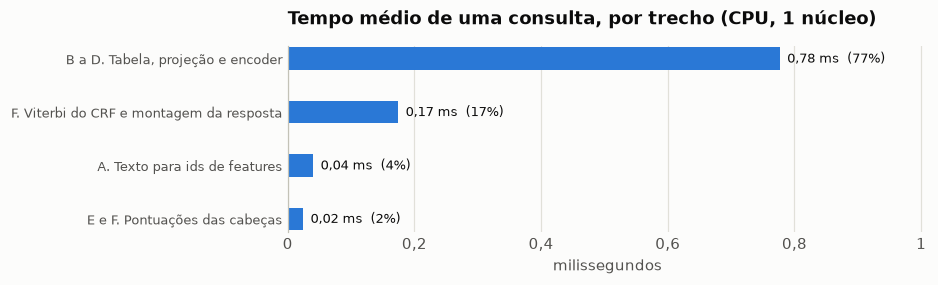


**Leitura.**

- Uma consulta leva cerca de **1,08 ms** (p50) num núcleo de CPU, sem GPU.
- O trecho mais caro é **B a D. Tabela, projeção e encoder**, com 77% do tempo.
- O Viterbi roda em Python, palavra por palavra; pesa 17% do total.
- O artigo do DIET reporta cerca de 80 ms por enunciado. Os números não são comparáveis: lá o modelo usava também embeddings pré-treinados e outra máquina. Serve só para dizer que a arquitetura, enxuta e do zero, não tem problema de latência.

A comparação de latência que importa, contra as LLMs, vem nas Etapas 5 e 9.


In [23]:
rng = np.random.default_rng(0)
consultas = [dev["utt"].iloc[i] for i in rng.integers(0, len(dev), 1074)]
trechos = {"A. Texto para ids de features": [], "B a D. Tabela, projeção e encoder": [],
           "E e F. Pontuações das cabeças": [], "F. Viterbi do CRF e montagem da resposta": []}
relogio = time.perf_counter_ns
modelo.eval()
with torch.no_grad():
    for i, texto in enumerate(consultas):
        t0 = relogio()
        lote = featurizador.montar([texto.split()])
        t1 = relogio()
        codificado = modelo.codificar(lote)
        t2 = relogio()
        pontos_intencao, pontos_tags = modelo._pontuar(codificado)
        t3 = relogio()
        pontos_intencao.argmax(dim=1).tolist()
        [rotulos["tags"][t] for t in modelo.crf.decodificar(pontos_tags, codificado["real"])[0]]
        t4 = relogio()
        if i >= 50:  # aquecimento
            for nome, (a, b) in zip(trechos, ((t0, t1), (t1, t2), (t2, t3), (t3, t4))):
                trechos[nome].append((b - a) / 1e6)

medias = pd.Series({nome: float(np.mean(v)) for nome, v in trechos.items()})
fig, ax = visual.barras_ranqueadas(
    medias, "Tempo médio de uma consulta, por trecho (CPU, 1 núcleo)", "milissegundos",
    destacar={nome: f"{num(v, 2)} ms  ({pts(v / medias.sum(), 0)}%)" for nome, v in medias.items()},
)
ax.xaxis.set_major_formatter(visual.VIRGULA)
ax.margins(x=0.3)
visual.salvar(fig, PASTA, "tempo_por_trecho")
plt.show()

maior_trecho = medias.idxmax()
display(Markdown(f"""
**Leitura.**

- Uma consulta leva cerca de **{num(linha['latencia_p50_ms'], 2)} ms** (p50) num núcleo de CPU, sem GPU.
- O trecho mais caro é **{maior_trecho}**, com {pts(medias.max() / medias.sum(), 0)}% do tempo.
- O Viterbi roda em Python, palavra por palavra; pesa {pts(medias['F. Viterbi do CRF e montagem da resposta'] / medias.sum(), 0)}% do total.
- O artigo do DIET reporta cerca de 80 ms por enunciado. Os números não são comparáveis: lá o modelo usava também embeddings pré-treinados e outra máquina. Serve só para dizer que a arquitetura, enxuta e do zero, não tem problema de latência.

A comparação de latência que importa, contra as LLMs, vem nas Etapas 5 e 9.
"""))

## 13. O que vem do artigo e o que é escolha deste projeto

A lista completa, para que qualquer número futuro possa ser atribuído à decisão certa.

In [24]:
c = config
decisoes = pd.DataFrame([
    ("Features: palavra + n-gramas de até 5 caracteres", "n ≤ 5", "Artigo", ""),
    ("Dropout nos features esparsos", num(c.dropout_features), "Artigo; taxa da referência", "O artigo não informa a taxa"),
    ("Token CLS ao final da sentença", "sim", "Artigo", ""),
    ("Transformer", f"{c.n_camadas} blocos, dimensão {c.d_modelo}", "Artigo", ""),
    ("Posição relativa na atenção", f"distância até ±{c.distancia_max}", "Artigo; alcance da referência", "O artigo não informa o alcance"),
    ("CRF na cabeça de entidades", "sim", "Artigo", ""),
    ("Espaço de comparação de intenção e máscara", f"{c.d_rotulo} dimensões", "Artigo", ""),
    ("Máscara", f"{c.p_mascara:.0%} das palavras; 70/10/20", "Artigo", ""),
    ("Perda total", "soma das três perdas", "Artigo", ""),
    ("Cabeças de atenção", str(c.n_cabecas), "Referência (Rasa)", "O artigo não informa"),
    ("Dimensão da tabela de features", str(c.d_features), "Referência (Rasa)", "O artigo não informa"),
    ("Dropout do encoder", num(c.dropout), "Referência (Rasa)", "O artigo não informa"),
    ("Rede densa do bloco", f"{c.d_ffn}, ReLU", "Vaswani et al.", "Proporção de 4 vezes e ativação originais"),
    ("Normalização antes da subcamada", "sim", "Escolha (Xiong et al.)", "Treino estável sem aquecimento"),
    ("Valor inicial do CLS", "média dos vetores das palavras", "Adaptação do artigo", "É a regra que o artigo usa para vetores sem contexto"),
    ("Contagem mínima de um feature", "2", "Escolha", "Feature visto uma vez não generaliza"),
    ("Intenções erradas na perda", "todas as outras", "Desvio", "Com 60 intenções é a versão exata; o artigo amostra"),
    ("Palavras erradas na perda de máscara", "as outras escondidas do lote", "Desvio", "O artigo sorteia"),
    ("Esquema de tags", "BIO, com regras fixas no CRF", "Desvio", f"{tipos_com_pouco} de {len(rotulos['slot_types'])} tipos têm menos de 100 exemplos"),
    ("Embeddings pré-treinados", "nenhum", "Escopo", "A proposta é uma rede do zero; o encoder pré-treinado é a Etapa 10"),
], columns=["decisão", "valor", "origem", "observação"]).set_index("decisão")
decisoes

,valor,origem,observação
decisão,,,
Features: palavra + n-gramas de até 5 caracteres,n ≤ 5,Artigo,
Dropout nos features esparsos,"0,2",Artigo; taxa da referência,O artigo não informa a taxa
Token CLS ao final da sentença,sim,Artigo,
Transformer,"2 blocos, dimensão 256",Artigo,
Posição relativa na atenção,distância até ±5,Artigo; alcance da referência,O artigo não informa o alcance
CRF na cabeça de entidades,sim,Artigo,
Espaço de comparação de intenção e máscara,20 dimensões,Artigo,
Máscara,15% das palavras; 70/10/20,Artigo,
Perda total,soma das três perdas,Artigo,


Dois avisos sobre os números do artigo, para calibrar a expectativa da Etapa 4:

- O F1 de entidades de 86,04 que o DIET reporta no NLU-Benchmark conta como acerto uma entidade prevista que apenas **se sobrepõe** à correta. A nossa régua exige limites exatos, que é mais dura.
- O artigo treina 200 épocas, com Adam, taxa de aprendizado de 0,001 e lote crescendo de 64 para 128, com lotes balanceados por intenção. Esses são os pontos de partida da Etapa 4.

## 14. Entrega

In [25]:
resultados.salvar([linha], PASTA)
decisoes.to_csv(PASTA / "decisoes.csv")

ficha = {
    "etapa": "03_arquitetura",
    "gerado_em": date.today().isoformat(),
    "entrada": ["entregas/01_dados", "entregas/02_avaliacao"],
    "artigo": "Bunk et al., DIET, arXiv 2004.09936",
    "config": config.como_dict(),
    "features": {"total": len(featurizador), "contagem_minima": 2, "n_max": featurizador.n_max},
    "saidas": {"intents": len(rotulos["intents"]), "tags": len(rotulos["tags"]), "esquema": "BIO"},
    "parametros": {"total": total, **{nome: int(v) for nome, v in partes.items()}},
    "medida": {"dispositivo": "cpu", "threads": 1, "consultas": eficiencia.CONSULTAS, "fonte_das_consultas": "dev"},
    "ambiente": {**eficiencia.ambiente(), "torch": torch.__version__},
}
(PASTA / "ficha.json").write_text(json.dumps(ficha, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

# O modelo sem treino, relido do disco, responde igual?
relido = SistemaDiet.carregar(PASTA / "modelo_sem_treino")
recarrega_ok = relido.prever(amostra) == sistema.prever(amostra)
print("Modelo relido do disco responde igual:", "sim" if recarrega_ok else "NÃO")

Modelo relido do disco responde igual: sim


### Critério de pronto

In [26]:
pronto = pd.Series({
    "CRF igual à força bruta (soma e melhor sequência)": bool(crf_ok),
    "Perdas iniciais a menos de 15% do valor teórico": bool(perdas_ok),
    "Gradiente em todos os parâmetros": gradiente_ok,
    "Resposta não depende do lote": lote_ok,
    "A rede decora 64 exemplos": decorar_ok,
    "O sistema passa pela régua e é relido do disco": bool(regua_ok and recarrega_ok),
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
CRF igual à força bruta (soma e melhor sequência),sim
Perdas iniciais a menos de 15% do valor teórico,sim
Gradiente em todos os parâmetros,sim
Resposta não depende do lote,sim
A rede decora 64 exemplos,sim
O sistema passa pela régua e é relido do disco,sim


## 15. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/03_arquitetura/RESUMO.md`.

In [27]:
camadas = [
    ("A", "Features", "Palavra + n-gramas de 1 a 5 caracteres", f"{n(len(featurizador))} features", "Palavras inéditas"),
    ("B", "Tabela de features", f"Soma dos vetores dos features, {c.d_features} dimensões", n(partes["B. Tabela de features"]), "Equivale à camada densa do DIET"),
    ("C", "Projeção e CLS", f"Linear para {c.d_modelo}; CLS = média das palavras, ao final", n(partes["C. Projeção e CLS"]), "Resumo do enunciado para a intenção"),
    ("D", "Encoder", f"{c.n_camadas} blocos Transformer, {c.n_cabecas} cabeças, posição relativa", n(partes["D. Encoder"]), "Contexto entre as palavras"),
    ("E", "Intenção", f"Produto interno num espaço de {c.d_rotulo} dimensões", n(partes["E. Cabeça de intenção"]), "Cabeça minúscula"),
    ("F", "Entidades", f"Pontuação por tag + CRF com regras BIO fixas", n(partes["F. Cabeça de entidades (CRF)"]), "Limites das entidades"),
    ("G", "Máscara", f"Adivinhar {c.p_mascara:.0%} das palavras escondidas (só no treino)", n(partes["G. Cabeça de máscara (só no treino)"]), "Regularização"),
]
tabela_camadas = "\n".join(f"| {a} | {b} | {d} | {e} | {f} |" for a, b, d, e, f in camadas)
tabela_tempo = "\n".join(f"| {nome} | {num(v, 2)} ms | {pts(v / medias.sum(), 0)}% |" for nome, v in medias.items())

resumo = f"""# Etapa 3 · Arquitetura: resumo da entrega

**Pergunta.** Que rede desenhar, do zero, para este problema?

**Resposta.** Uma reimplementação em PyTorch do DIET (Bunk et al., arXiv 2004.09936), sem nenhum peso pré-treinado: features de palavra e de caracteres, um encoder Transformer de {c.n_camadas} blocos com posição relativa, e duas cabeças treinadas juntas, uma para a intenção e um CRF para as entidades. São **{n(total)} parâmetros**, {num(xlmr / total, 0)} vezes menos que o XLM-R Base da referência publicada. A rede ainda **não foi treinada**; esta etapa entrega a rede e a prova de que está corretamente ligada.

![Arquitetura](figuras/arquitetura.png)

## As camadas

| | Camada | O que faz | Parâmetros | Para que serve |
|---|---|---|---|---|
{tabela_camadas}

## O que já se sabe sem treinar

- **Tamanho.** {pts(partes['B. Tabela de features'] / total, 0)}% dos parâmetros estão na tabela de features, e não no Transformer. A poda e a quantização (Etapas 7 e 8) precisam tratar a tabela para reduzir o modelo de verdade.
- **Latência.** {num(linha['latencia_p50_ms'], 2)} ms por consulta (p50) e {num(linha['latencia_p95_ms'], 2)} ms (p95), em 1 núcleo de CPU, uma consulta por vez. A linha de base leva {num(linha_de_base['latencia_p50_ms'], 2)} ms.
- **Disco.** {num(bytes_modelo / 1e6)} MB em ponto flutuante de 32 bits.

| Trecho da consulta | Tempo médio | Parte |
|---|---|---|
{tabela_tempo}

## A rede está bem ligada

| Teste | Resultado |
|---|---|
| CRF contra a força bruta | Soma e melhor sequência idênticas em todos os comprimentos testados |
| Perdas iniciais | Intenção {num(inicial['intencao'], 2)} (teoria {num(teoria['intencao'], 2)}); entidades {num(inicial['entidades'], 2)} (teoria {num(teoria['entidades'], 2)}); máscara {num(inicial['mascara'], 2)} (teoria {num(teoria['mascara'], 2)}) |
| Gradiente | Chega aos {len(list(modelo.named_parameters()))} tensores de parâmetros |
| Independência do lote | 200 enunciados com a mesma resposta juntos e um por um |
| Decorar 64 exemplos | Exact match de 100% a partir do passo {decorou_em} |

O pacote também tem {len(list((RAIZ / "tests").glob("test_*.py")))} arquivos de teste automático (`uv run pytest`).

## Desvios declarados em relação ao artigo

- **Todas as intenções na perda**, em vez de uma amostra das erradas. Com 60 intenções é a versão exata.
- **BIO com regras fixas no CRF**, em vez de BILOU: {tipos_com_pouco} dos {len(rotulos['slot_types'])} tipos de entidade têm menos de 100 exemplos.
- **Palavras erradas da máscara vêm do próprio lote**, em vez de sorteadas.
- **CLS começa como a média dos vetores das palavras**, que é a regra do artigo para vetores sem contexto.
- O que o artigo não informa (cabeças, dimensão da tabela, dropout, alcance da posição) usa o padrão da implementação de referência. A lista completa está em `decisoes.csv`.

## Para a Etapa 4 (treino com rótulos humanos)

Pontos de partida do artigo: Adam, taxa de aprendizado de 0,001, lote crescendo de 64 para 128, lotes balanceados por intenção, 200 épocas.

Comparações a decidir em `dev`, com a regra escrita antes do resultado:

1. Máscara ligada contra desligada.
2. Treino conjunto contra cada tarefa sozinha (a ablação central do DIET).
3. Com CRF contra sem CRF.

Aviso de expectativa: o F1 de entidades do DIET no NLU-Benchmark (86,04) conta sobreposição como acerto; a nossa régua exige limites exatos.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `ficha.json` | Configuração, vocabulário de features, parâmetros por parte, ambiente |
| `decisoes.csv` | Cada decisão de desenho, com valor, origem e observação |
| `resultados.csv` | A linha do modelo sem treino na régua (eficiência) |
| `modelo_sem_treino/` | Pesos iniciais, vocabulário de features e configuração |
| `figuras/` | Diagrama e gráficos deste notebook |
| `03_arquitetura.html` | Este notebook executado, para leitura |

Para criar a rede nas próximas etapas:

```python
from especialista.modelos.diet import Config, SistemaDiet

sistema = SistemaDiet.novo(treino, rotulos, Config(), semente=0)
perdas = sistema.modelo.perda(sistema.lote(treino.iloc[:64]))   # intenção, entidades, máscara, total
previsoes = sistema.prever(["acorda-me às nove da manhã"])
```
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 3 · Arquitetura: resumo da entrega

**Pergunta.** Que rede desenhar, do zero, para este problema?

**Resposta.** Uma reimplementação em PyTorch do DIET (Bunk et al., arXiv 2004.09936), sem nenhum peso pré-treinado: features de palavra e de caracteres, um encoder Transformer de 2 blocos com posição relativa, e duas cabeças treinadas juntas, uma para a intenção e um CRF para as entidades. São **4.895.834 parâmetros**, 55 vezes menos que o XLM-R Base da referência publicada. A rede ainda **não foi treinada**; esta etapa entrega a rede e a prova de que está corretamente ligada.

![Arquitetura](figuras/arquitetura.png)

## As camadas

| | Camada | O que faz | Parâmetros | Para que serve |
|---|---|---|---|---|
| A | Features | Palavra + n-gramas de 1 a 5 caracteres | 25.202 features | Palavras inéditas |
| B | Tabela de features | Soma dos vetores dos features, 128 dimensões | 3.225.856 | Equivale à camada densa do DIET |
| C | Projeção e CLS | Linear para 256; CLS = média das palavras, ao final | 33.280 | Resumo do enunciado para a intenção |
| D | Encoder | 2 blocos Transformer, 4 cabeças, posição relativa | 1.581.440 | Contexto entre as palavras |
| E | Intenção | Produto interno num espaço de 20 dimensões | 6.340 | Cabeça minúscula |
| F | Entidades | Pontuação por tag + CRF com regras BIO fixas | 41.070 | Limites das entidades |
| G | Máscara | Adivinhar 15% das palavras escondidas (só no treino) | 7.848 | Regularização |

## O que já se sabe sem treinar

- **Tamanho.** 66% dos parâmetros estão na tabela de features, e não no Transformer. A poda e a quantização (Etapas 7 e 8) precisam tratar a tabela para reduzir o modelo de verdade.
- **Latência.** 1,08 ms por consulta (p50) e 1,45 ms (p95), em 1 núcleo de CPU, uma consulta por vez. A linha de base leva 0,82 ms.
- **Disco.** 19,9 MB em ponto flutuante de 32 bits.

| Trecho da consulta | Tempo médio | Parte |
|---|---|---|
| A. Texto para ids de features | 0,04 ms | 4% |
| B a D. Tabela, projeção e encoder | 0,78 ms | 77% |
| E e F. Pontuações das cabeças | 0,02 ms | 2% |
| F. Viterbi do CRF e montagem da resposta | 0,17 ms | 17% |

## A rede está bem ligada

| Teste | Resultado |
|---|---|
| CRF contra a força bruta | Soma e melhor sequência idênticas em todos os comprimentos testados |
| Perdas iniciais | Intenção 4,11 (teoria 4,09); entidades 25,98 (teoria 25,88); máscara 4,40 (teoria 4,37) |
| Gradiente | Chega aos 53 tensores de parâmetros |
| Independência do lote | 200 enunciados com a mesma resposta juntos e um por um |
| Decorar 64 exemplos | Exact match de 100% a partir do passo 75 |

O pacote também tem 4 arquivos de teste automático (`uv run pytest`).

## Desvios declarados em relação ao artigo

- **Todas as intenções na perda**, em vez de uma amostra das erradas. Com 60 intenções é a versão exata.
- **BIO com regras fixas no CRF**, em vez de BILOU: 30 dos 55 tipos de entidade têm menos de 100 exemplos.
- **Palavras erradas da máscara vêm do próprio lote**, em vez de sorteadas.
- **CLS começa como a média dos vetores das palavras**, que é a regra do artigo para vetores sem contexto.
- O que o artigo não informa (cabeças, dimensão da tabela, dropout, alcance da posição) usa o padrão da implementação de referência. A lista completa está em `decisoes.csv`.

## Para a Etapa 4 (treino com rótulos humanos)

Pontos de partida do artigo: Adam, taxa de aprendizado de 0,001, lote crescendo de 64 para 128, lotes balanceados por intenção, 200 épocas.

Comparações a decidir em `dev`, com a regra escrita antes do resultado:

1. Máscara ligada contra desligada.
2. Treino conjunto contra cada tarefa sozinha (a ablação central do DIET).
3. Com CRF contra sem CRF.

Aviso de expectativa: o F1 de entidades do DIET no NLU-Benchmark (86,04) conta sobreposição como acerto; a nossa régua exige limites exatos.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `ficha.json` | Configuração, vocabulário de features, parâmetros por parte, ambiente |
| `decisoes.csv` | Cada decisão de desenho, com valor, origem e observação |
| `resultados.csv` | A linha do modelo sem treino na régua (eficiência) |
| `modelo_sem_treino/` | Pesos iniciais, vocabulário de features e configuração |
| `figuras/` | Diagrama e gráficos deste notebook |
| `03_arquitetura.html` | Este notebook executado, para leitura |

Para criar a rede nas próximas etapas:

```python
from especialista.modelos.diet import Config, SistemaDiet

sistema = SistemaDiet.novo(treino, rotulos, Config(), semente=0)
perdas = sistema.modelo.perda(sistema.lote(treino.iloc[:64]))   # intenção, entidades, máscara, total
previsoes = sistema.prever(["acorda-me às nove da manhã"])
```


In [28]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file())
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos],
)

,tamanho (KB)
entregas/03_arquitetura/RESUMO.md,4.7
entregas/03_arquitetura/decisoes.csv,1.6
entregas/03_arquitetura/ficha.json,1.2
entregas/03_arquitetura/figuras/arquitetura.png,129.6
entregas/03_arquitetura/figuras/decorar.png,131.2
entregas/03_arquitetura/figuras/parametros.png,61.8
entregas/03_arquitetura/figuras/posicao_relativa.png,77.7
entregas/03_arquitetura/figuras/tempo_por_trecho.png,50.9
entregas/03_arquitetura/modelo_sem_treino/config.json,3.9
entregas/03_arquitetura/modelo_sem_treino/features.json,262.8
